# Separação e União de Datasets


# **Detecção de fatos e fake news**

Link da base de dados: https://drive.google.com/drive/folders/1iy3D4_HLuIVeG5mwELlWZ_FDsFzvKBw8?usp=sharing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os, sys, json, requests, re
import json
import pandas as pd
import spacy
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import math
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import RSLPStemmer
import unicodedata
import json
from networkx.readwrite import json_graph
nltk.download('stopwords')
nltk.download('rslp')

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)
import ast

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\andre\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package rslp to
[nltk_data]     C:\Users\andre\AppData\Roaming\nltk_data...
[nltk_data]   Package rslp is already up-to-date!


In [2]:
pd.reset_option('display.max_colwidth')

In [3]:
# Não irá usar esta função

# def pre_processamento(texto):
#     #if pd.isna(texto):
#     #      return ""
#     # Converter para minúsculas
#     texto = texto.lower()
#     # Remover acentos e caracteres especiais
#     texto = unicodedata.normalize('NFKD', texto).encode('ASCII', 'ignore').decode('ASCII')
#     # Remover caracteres não alfabéticos e números
#     texto = re.sub(r'[^a-z\s]', ' ', texto)
#     # Remover espaços em excesso
#     texto = re.sub(r'\s+', ' ', texto).strip()
#     # Tokenização
#     tokens = texto.split()
#     # Remover stopwords
#     stop_words = set(stopwords.words('portuguese'))
#     tokens = [palavra for palavra in tokens if palavra not in stop_words]
#     return ' '.join(tokens)

In [4]:
def normalizar_rating(x):
    if isinstance(x, str):
        x = ast.literal_eval(x)   # transforma "['Enganoso']" em ['Enganoso']
    return [item.lower() for item in x]

In [5]:
caminho_arquivo = "saida-openrouter.jsonl"

df = pd.read_json(caminho_arquivo, lines=True)

df["rating"] = df["rating"].apply(
    lambda x: [item.lower() for item in ast.literal_eval(x)]
)

# Remove as duplicatas geradas pelo extrator.py
df = df.drop_duplicates(subset=['url', 'title'], keep='first')


print(df.shape)
#Lista 10 primeiros registros
df[['boato', 'fatos', 'source_name', 'title', 'categories',
       'url', 'rating']].head(10)

(11647, 8)


,boato,fatos,source_name,title,categories,url,rating
0,Uso da cloroquina no início da covid-19 elimin...,[A médica Helen Brandão enviou 34 estudos para...,COMPROVA,Médica cita estudos não conclusivos para suger...,['Pandemia'],https://projetocomprova.com.br/publica%C3%A7%C...,[enganoso]
1,O Exército está fazendo melhorias na Transamaz...,[Parte dos trechos das gravações utilizadas no...,COMPROVA,Post mostra imagens de outras estradas para af...,['Políticas públicas'],https://projetocomprova.com.br/publica%C3%A7%C...,[falso]
2,"Bolsonaro liberou, via Ancine, 530 mil reais p...",[A Ancine aprovou em 2019 a captação de 530 mi...,COMPROVA,Publicações enganam ao associar Bolsonaro à ap...,['Políticas públicas'],https://projetocomprova.com.br/publica%C3%A7%C...,[enganoso]
3,"O governador de São Paulo, João Doria, tomou a...",[A imagem que circula nas redes sociais é de u...,COMPROVA,"Imagem de Doria tomando vacina é de março, ant...",['Pandemia'],https://projetocomprova.com.br/publica%C3%A7%C...,[enganoso]
4,Covid-19 tem cura com um coquetel de hidroxicl...,[Tanto a Organização Mundial da Saúde (OMS) qu...,COMPROVA,Médica usa informações falsas em vídeo para fa...,['Pandemia'],https://projetocomprova.com.br/publica%C3%A7%C...,[falso]
5,"O prefeito de São Paulo, Bruno Covas, anuncia ...",[O anúncio da adoção da cloroquina como parte ...,COMPROVA,Eduardo Bolsonaro posta vídeo antigo sobre lib...,['Pandemia'],https://projetocomprova.com.br/publica%C3%A7%C...,[enganoso]
6,O uso da hidroxicloroquina é responsável pelo ...,[A agência estatal turca Anadolu publicou uma ...,COMPROVA,Site engana ao afirmar que baixa mortalidade p...,['Pandemia'],https://projetocomprova.com.br/publica%C3%A7%C...,[enganoso]
7,Vacina chinesa contra a covid-19 chegou ao Bra...,[A vacina chegou ao Brasil em 20 de julho de 2...,COMPROVA,Vacinas para covid-19 que chegaram ao Brasil s...,['Pandemia'],https://projetocomprova.com.br/publica%C3%A7%C...,[enganoso]
8,O real será substituído por uma nova moeda cha...,[O Banco Central é o responsável exclusivo pel...,COMPROVA,Brasil não terá uma nova moeda lastreada em ni...,['Políticas públicas'],https://projetocomprova.com.br/publica%C3%A7%C...,[falso]
9,A vacina contra a covid-19 desenvolvida pela U...,[As células utilizadas na produção da vacina s...,COMPROVA,Tuíte engana ao afirmar que vacinas usam célul...,['Pandemia'],https://projetocomprova.com.br/publica%C3%A7%C...,[enganoso]


In [6]:
#Fatos são concatenados em um único texto
df['fato'] = df['fatos'].apply(lambda x: ' '.join(x))

#Exemplo
print("Fato: ", df['fato'][0])
print("Boato: ", df['boato'][0])

Fato:  A médica Helen Brandão enviou 34 estudos para justificar seu texto, mas nenhum é conclusivo sobre a eficácia dos medicamentos citados. A venda da cloroquina e da ivermectina não foi proibida no Brasil. A Anvisa publicou uma norma em 24 de julho para que esses medicamentos sejam vendidos com receita médica. O Ministério da Saúde inclui a cloroquina no protocolo de tratamento para pacientes leves da covid-19. A médica Helen Brandão é graduada pela Universidade Federal de Goiás e tem pós-graduação em Dermatologia e Medicina Estética. A Agência Nacional de Vigilância Sanitária (Anvisa) exige que as farmácias retenham receitas das pessoas que queiram comprar cloroquina, hidroxicloroquina, nitazoxanida e ivermectina.
Boato:  Uso da cloroquina no início da covid-19 elimina o novo coronavírus.


In [7]:
#"Explode" o dataset para que cada item da lista de fatos vire uma nova instância do dataframe
#df_explodido = df.explode("fatos").reset_index(drop=True)
#df_explodido = df_explodido.rename(columns={"fatos": "fato"})
#df_explodido = df_explodido.dropna(subset=["fato"])
#print(df_explodido.shape)
#df_explodido.head(5)

In [8]:
#Quantidade de rating nulo = 0
#df_explodido["rating"].isna().sum()

In [9]:
df["rating"].apply(tuple).unique()#Valores únicos da coluna rating, é preciso investigar como está na base de dados e como a LLM tratou

array([('enganoso',), ('falso',), ('comprovado',), ('contexto errado',),
       ('evidência comprovada',), ('fora de contexto',), ('fake',),
       ('fake', 'nao e bem assim', 'nao e bem assim', 'fato', 'nao e bem assim', 'nao e bem assim', 'fato', 'fato', 'nao e bem assim'),
       ('fake', 'nao e bem assim', 'nao e bem assim', 'fato', 'nao e bem assim', 'fake', 'fake', 'fake', 'fake', 'fato', 'nao e bem assim', 'fato', 'fake', 'fato', 'nao e bem assim', 'fake', 'nao e bem assim', 'nao e bem assim', 'nao e bem assim', 'nao e bem assim', 'fake', 'fake'),
       ('nao e bem assim', 'fato', 'nao e bem assim', 'nao e bem assim', 'fake', 'fato', 'fato', 'fake', 'nao e bem assim', 'nao e bem assim', 'nao e bem assim', 'fake', 'nao e bem assim', 'fato', 'nao e bem assim', 'nao e bem assim', 'fake', 'fato', 'fato'),
       ('fake', 'fato', 'fato', 'fake', 'nao e bem assim', 'fake', 'fake', 'fato', 'nao e bem assim', 'fake', 'fato', 'fake', 'nao e bem assim', 'fake', 'fato', 'nao e bem assim',

In [10]:
termos_falsidade = [
    "falso", 
    "fake", 
    "boato",
    "enganoso", 
    "fora de contexto", 
    "contexto errado", 
    "distorcido",
    "impreciso",
    "exagerado",
    "insustentável",
    "contraditório",
    "não é bem assim"
]

termos_verdade = [
    "verdadeiro",
    "fato",
    "comprovado",
    "evidência comprovada"
]

Exemplo: link https://g1.globo.com/fato-ou-fake/noticia/2018/09/25/veja-o-que-e-fato-ou-fake-na-entrevista-de-garotinho-ao-g1-e-a-cbn.ghtml

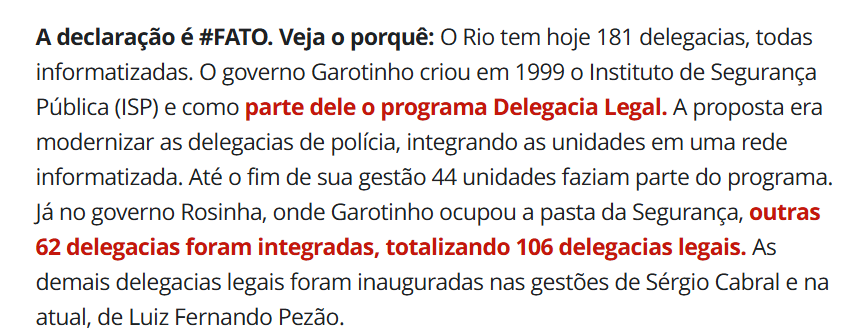

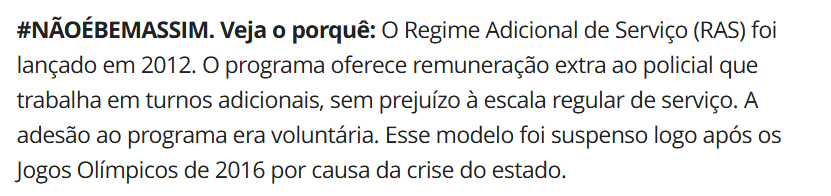


In [11]:
#Cria primeiro dataset a partir dos fatos
dataset_fatos = df[['fato', 'url', 'text_news', 'source_name', 'title', 'categories', 'rating']].copy()
dataset_fatos["label"] = "fato"
dataset_fatos = dataset_fatos.rename(columns={"fato": "text"})
print(dataset_fatos.shape)
dataset_fatos.head(5)

(11647, 8)


,text,url,text_news,source_name,title,categories,rating,label
0,A médica Helen Brandão enviou 34 estudos para ...,https://projetocomprova.com.br/publica%C3%A7%C...,"Procurada pelo Comprova, médica enviou 34 estu...",COMPROVA,Médica cita estudos não conclusivos para suger...,['Pandemia'],[enganoso],fato
1,Parte dos trechos das gravações utilizadas no ...,https://projetocomprova.com.br/publica%C3%A7%C...,Parte dos trechos das gravações utilizadas no ...,COMPROVA,Post mostra imagens de outras estradas para af...,['Políticas públicas'],[falso],fato
2,A Ancine aprovou em 2019 a captação de 530 mil...,https://projetocomprova.com.br/publica%C3%A7%C...,Ancine aprovou em 2019 a captação de 530 mil r...,COMPROVA,Publicações enganam ao associar Bolsonaro à ap...,['Políticas públicas'],[enganoso],fato
3,A imagem que circula nas redes sociais é de um...,https://projetocomprova.com.br/publica%C3%A7%C...,Imagem que circula nas redes sociais é de um t...,COMPROVA,"Imagem de Doria tomando vacina é de março, ant...",['Pandemia'],[enganoso],fato
4,Tanto a Organização Mundial da Saúde (OMS) qua...,https://projetocomprova.com.br/publica%C3%A7%C...,Ao contrário do que afirma uma médica em vídeo...,COMPROVA,Médica usa informações falsas em vídeo para fa...,['Pandemia'],[falso],fato


In [12]:
#Filtra dataset com boatos que são verdadeiros
df_filtrado_boatos_verdadeiros = df[
    df["rating"].apply(
        lambda x: len(x) == 1 and x[0] in termos_verdade
    )
]

print(df_filtrado_boatos_verdadeiros.shape)
df_filtrado_boatos_verdadeiros

(63, 9)


,boato,fatos,text_news,source_name,title,categories,url,rating,fato
24,O presidente Jair Bolsonaro liberou um fundo d...,[O projeto foi apresentado no plenário da Câma...,Projeto foi apresentado no plenário da Câmara ...,COMPROVA,É verdadeiro que Bolsonaro tenha liberado auxí...,['Pandemia'],https://projetocomprova.com.br/publica%C3%A7%C...,[comprovado],O projeto foi apresentado no plenário da Câmar...
38,Trecho da BR-163 foi asfaltado em apenas 8 mes...,[O trecho da BR-163 entre Novo Progresso e Mor...,Trecho que aparece em montagem compartilhada n...,COMPROVA,Comprovado: trecho da BR-163 foi asfaltado no ...,['Políticas públicas'],https://projetocomprova.com.br/publica%C3%A7%C...,[comprovado],O trecho da BR-163 entre Novo Progresso e Mora...
59,O resultado do Ideb teve o maior salto dos últ...,"[O resultado do Ideb de 2019 foi de 4,2, super...",O índice é divulgado a cada dois anos. O resul...,COMPROVA,É verdade que o Ensino Médio apresentou melhor...,['Políticas públicas'],https://projetocomprova.com.br/publica%C3%A7%C...,[comprovado],"O resultado do Ideb de 2019 foi de 4,2, superi..."
62,Uma emissora de televisão alemã exibiu uma rep...,[A emissora alemã N-TV utilizou a imagem de el...,Emissora alemã confirmou ao Comprova a exibiçã...,COMPROVA,TV alemã exibiu elefantes ao falar sobre queim...,['Políticas públicas'],https://projetocomprova.com.br/publica%C3%A7%C...,[comprovado],A emissora alemã N-TV utilizou a imagem de ele...
133,Mortes de policiais federais são menos frequen...,"[Em 2017, não houve mortes de policiais federa...",A publicação apresenta dados próximos aos núme...,COMPROVA,Postagem sobre mortes de pedreiros e policiais...,['Políticas públicas'],https://projetocomprova.com.br/publica%C3%A7%C...,[evidência comprovada],"Em 2017, não houve mortes de policiais federai..."
...,...,...,...,...,...,...,...,...,...
10629,Cerveja pode retardar o envelhecimento devido ...,[O estudo foi publicado em 2013 por cientistas...,Circula nas redes sociais a imagem de uma repo...,lupa,#CaiuNaRede: É verdadeiro estudo que aponta qu...,[],https://piaui.folha.uol.com.br/lupa/2020/09/30...,[verdadeiro],O estudo foi publicado em 2013 por cientistas ...
10701,Existem várias afirmações falsas sobre o cânce...,[Não existe relação entre câncer de mama e pie...,"No Brasil, 79 em cada 100 mil mulheres são dia...",lupa,No Twitter: quatro mentiras e uma verdade sobr...,[],https://piaui.folha.uol.com.br/lupa/2017/10/10...,[verdadeiro],Não existe relação entre câncer de mama e pier...
11249,O coordenador da força-tarefa da Operação Lava...,"[No dia 3 de outubro de 2017, Deltan Dallagnol...",Circula pelas redes sociais um post que teria ...,lupa,#Verificamos: É verdadeiro que Dallagnol chamo...,[],https://piaui.folha.uol.com.br/lupa/2019/06/13...,[verdadeiro],"No dia 3 de outubro de 2017, Deltan Dallagnol ..."
11423,O número de casos de Aids aumentou no Brasil e...,[A taxa de detecção de Aids vem diminuindo no ...,"O número de casos de Aids diminuiu 5,1% no Bra...",lupa,"No Twitter, quatro mentiras e uma verdade sobr...",[],https://piaui.folha.uol.com.br/lupa/2017/12/05...,[verdadeiro],A taxa de detecção de Aids vem diminuindo no p...


In [13]:
#Cria segundo dataset a partir dos boatos verdadeiros
dataset_boatos_verdadeiros = df_filtrado_boatos_verdadeiros[['boato', 'url', 'text_news', 'source_name', 'title', 'categories', 'rating']].copy()
dataset_boatos_verdadeiros["label"] = "fato"
dataset_boatos_verdadeiros = dataset_boatos_verdadeiros.rename(columns={"boato": "text"})
print(dataset_boatos_verdadeiros.shape)
dataset_boatos_verdadeiros.head(5)

(63, 8)


,text,url,text_news,source_name,title,categories,rating,label
24,O presidente Jair Bolsonaro liberou um fundo d...,https://projetocomprova.com.br/publica%C3%A7%C...,Projeto foi apresentado no plenário da Câmara ...,COMPROVA,É verdadeiro que Bolsonaro tenha liberado auxí...,['Pandemia'],[comprovado],fato
38,Trecho da BR-163 foi asfaltado em apenas 8 mes...,https://projetocomprova.com.br/publica%C3%A7%C...,Trecho que aparece em montagem compartilhada n...,COMPROVA,Comprovado: trecho da BR-163 foi asfaltado no ...,['Políticas públicas'],[comprovado],fato
59,O resultado do Ideb teve o maior salto dos últ...,https://projetocomprova.com.br/publica%C3%A7%C...,O índice é divulgado a cada dois anos. O resul...,COMPROVA,É verdade que o Ensino Médio apresentou melhor...,['Políticas públicas'],[comprovado],fato
62,Uma emissora de televisão alemã exibiu uma rep...,https://projetocomprova.com.br/publica%C3%A7%C...,Emissora alemã confirmou ao Comprova a exibiçã...,COMPROVA,TV alemã exibiu elefantes ao falar sobre queim...,['Políticas públicas'],[comprovado],fato
133,Mortes de policiais federais são menos frequen...,https://projetocomprova.com.br/publica%C3%A7%C...,A publicação apresenta dados próximos aos núme...,COMPROVA,Postagem sobre mortes de pedreiros e policiais...,['Políticas públicas'],[evidência comprovada],fato


In [14]:
# Filtra dataset com boatos que são falsos.
# Basta que tenha uma das palavras em termos_falsidade na lista rating

df_filtrado_fake = df[
    df["rating"].apply(
        lambda x: any(v in x for v in termos_falsidade)
    )
]
df_filtrado_fake

,boato,fatos,text_news,source_name,title,categories,url,rating,fato
0,Uso da cloroquina no início da covid-19 elimin...,[A médica Helen Brandão enviou 34 estudos para...,"Procurada pelo Comprova, médica enviou 34 estu...",COMPROVA,Médica cita estudos não conclusivos para suger...,['Pandemia'],https://projetocomprova.com.br/publica%C3%A7%C...,[enganoso],A médica Helen Brandão enviou 34 estudos para ...
1,O Exército está fazendo melhorias na Transamaz...,[Parte dos trechos das gravações utilizadas no...,Parte dos trechos das gravações utilizadas no ...,COMPROVA,Post mostra imagens de outras estradas para af...,['Políticas públicas'],https://projetocomprova.com.br/publica%C3%A7%C...,[falso],Parte dos trechos das gravações utilizadas no ...
2,"Bolsonaro liberou, via Ancine, 530 mil reais p...",[A Ancine aprovou em 2019 a captação de 530 mi...,Ancine aprovou em 2019 a captação de 530 mil r...,COMPROVA,Publicações enganam ao associar Bolsonaro à ap...,['Políticas públicas'],https://projetocomprova.com.br/publica%C3%A7%C...,[enganoso],A Ancine aprovou em 2019 a captação de 530 mil...
3,"O governador de São Paulo, João Doria, tomou a...",[A imagem que circula nas redes sociais é de u...,Imagem que circula nas redes sociais é de um t...,COMPROVA,"Imagem de Doria tomando vacina é de março, ant...",['Pandemia'],https://projetocomprova.com.br/publica%C3%A7%C...,[enganoso],A imagem que circula nas redes sociais é de um...
4,Covid-19 tem cura com um coquetel de hidroxicl...,[Tanto a Organização Mundial da Saúde (OMS) qu...,Ao contrário do que afirma uma médica em vídeo...,COMPROVA,Médica usa informações falsas em vídeo para fa...,['Pandemia'],https://projetocomprova.com.br/publica%C3%A7%C...,[falso],Tanto a Organização Mundial da Saúde (OMS) qua...
...,...,...,...,...,...,...,...,...,...
11644,O câncer de pele não é perigoso. O câncer de p...,"[Em 2018, mais de 170 mil brasileiros foram di...",O câncer de pele é o tipo de câncer mais frequ...,lupa,Câncer de pele mata? Só ocorre por exposição a...,[],https://piaui.folha.uol.com.br/lupa/2020/03/05...,"[falso, falso, verdadeiro, exagerado, verdadeiro]","Em 2018, mais de 170 mil brasileiros foram dia..."
11645,Os ovos da China são feitos de plástico e vend...,[As imagens que circularam online eram de fabr...,Vocês já viram a escolha de todos os integrant...,boatos,Os 5 textos mais lidos de 2018 no Boatos.org,Lista,https://www.boatos.org/lista/textos-mais-lidos...,[boato],As imagens que circularam online eram de fabri...
11646,Alexandre Frota virou motorista da Uber por nã...,[Alexandre Frota não tinha virado motorista de...,"Para mim, a prova viva de que o tempo passa rá...",boatos,"O melhor do Boatos.org em 2018, por Hellen Biz...",Lista,https://www.boatos.org/lista/melhor-boatos-201...,[boato],Alexandre Frota não tinha virado motorista de ...
11647,Bruno Covas: 'Pílulas de paracetamol estão inf...,[Nota da Anvisa de 15 de março afirma não have...,Os dois candidatos que disputam a Prefeitura d...,fato-ou-fake,Veja o que é #FATO ou #FAKE nas declarações do...,None,https://g1.globo.com/fato-ou-fake/noticia/2020...,"[nao e bem assim, fato, nao e bem assim, fake,...",Nota da Anvisa de 15 de março afirma não haver...


In [15]:
#Cria terceiro dataset a partir dos boatos falsos
dataset_boatos_falsos = df_filtrado_fake[['boato', 'url', 'text_news', 'source_name', 'title', 'categories', 'rating']].copy()
dataset_boatos_falsos["label"] = "fake"
dataset_boatos_falsos = dataset_boatos_falsos.rename(columns={"boato": "text"})
dataset_boatos_falsos.head(5)

,text,url,text_news,source_name,title,categories,rating,label
0,Uso da cloroquina no início da covid-19 elimin...,https://projetocomprova.com.br/publica%C3%A7%C...,"Procurada pelo Comprova, médica enviou 34 estu...",COMPROVA,Médica cita estudos não conclusivos para suger...,['Pandemia'],[enganoso],fake
1,O Exército está fazendo melhorias na Transamaz...,https://projetocomprova.com.br/publica%C3%A7%C...,Parte dos trechos das gravações utilizadas no ...,COMPROVA,Post mostra imagens de outras estradas para af...,['Políticas públicas'],[falso],fake
2,"Bolsonaro liberou, via Ancine, 530 mil reais p...",https://projetocomprova.com.br/publica%C3%A7%C...,Ancine aprovou em 2019 a captação de 530 mil r...,COMPROVA,Publicações enganam ao associar Bolsonaro à ap...,['Políticas públicas'],[enganoso],fake
3,"O governador de São Paulo, João Doria, tomou a...",https://projetocomprova.com.br/publica%C3%A7%C...,Imagem que circula nas redes sociais é de um t...,COMPROVA,"Imagem de Doria tomando vacina é de março, ant...",['Pandemia'],[enganoso],fake
4,Covid-19 tem cura com um coquetel de hidroxicl...,https://projetocomprova.com.br/publica%C3%A7%C...,Ao contrário do que afirma uma médica em vídeo...,COMPROVA,Médica usa informações falsas em vídeo para fa...,['Pandemia'],[falso],fake


In [16]:
#Concatena os 3 datasets
dataset = pd.concat([ dataset_fatos, dataset_boatos_verdadeiros, dataset_boatos_falsos], ignore_index=True)
print(dataset.shape)
dataset

(23167, 8)


,text,url,text_news,source_name,title,categories,rating,label
0,A médica Helen Brandão enviou 34 estudos para ...,https://projetocomprova.com.br/publica%C3%A7%C...,"Procurada pelo Comprova, médica enviou 34 estu...",COMPROVA,Médica cita estudos não conclusivos para suger...,['Pandemia'],[enganoso],fato
1,Parte dos trechos das gravações utilizadas no ...,https://projetocomprova.com.br/publica%C3%A7%C...,Parte dos trechos das gravações utilizadas no ...,COMPROVA,Post mostra imagens de outras estradas para af...,['Políticas públicas'],[falso],fato
2,A Ancine aprovou em 2019 a captação de 530 mil...,https://projetocomprova.com.br/publica%C3%A7%C...,Ancine aprovou em 2019 a captação de 530 mil r...,COMPROVA,Publicações enganam ao associar Bolsonaro à ap...,['Políticas públicas'],[enganoso],fato
3,A imagem que circula nas redes sociais é de um...,https://projetocomprova.com.br/publica%C3%A7%C...,Imagem que circula nas redes sociais é de um t...,COMPROVA,"Imagem de Doria tomando vacina é de março, ant...",['Pandemia'],[enganoso],fato
4,Tanto a Organização Mundial da Saúde (OMS) qua...,https://projetocomprova.com.br/publica%C3%A7%C...,Ao contrário do que afirma uma médica em vídeo...,COMPROVA,Médica usa informações falsas em vídeo para fa...,['Pandemia'],[falso],fato
...,...,...,...,...,...,...,...,...
23162,O câncer de pele não é perigoso. O câncer de p...,https://piaui.folha.uol.com.br/lupa/2020/03/05...,O câncer de pele é o tipo de câncer mais frequ...,lupa,Câncer de pele mata? Só ocorre por exposição a...,[],"[falso, falso, verdadeiro, exagerado, verdadeiro]",fake
23163,Os ovos da China são feitos de plástico e vend...,https://www.boatos.org/lista/textos-mais-lidos...,Vocês já viram a escolha de todos os integrant...,boatos,Os 5 textos mais lidos de 2018 no Boatos.org,Lista,[boato],fake
23164,Alexandre Frota virou motorista da Uber por nã...,https://www.boatos.org/lista/melhor-boatos-201...,"Para mim, a prova viva de que o tempo passa rá...",boatos,"O melhor do Boatos.org em 2018, por Hellen Biz...",Lista,[boato],fake
23165,Bruno Covas: 'Pílulas de paracetamol estão inf...,https://g1.globo.com/fato-ou-fake/noticia/2020...,Os dois candidatos que disputam a Prefeitura d...,fato-ou-fake,Veja o que é #FATO ou #FAKE nas declarações do...,None,"[nao e bem assim, fato, nao e bem assim, fake,...",fake


In [17]:
# Mostra o balanceamento dos dados (Quantos Fatos vs Quantos Fakes)
dataset['label'].value_counts()

label
fato    11710
fake    11457
Name: count, dtype: int64

In [18]:
# Não será usado

# # ==========================================
# # O MOTOR DE NLP (Limpeza do Texto)
# # ==========================================
# print("\nIniciando a limpeza de PLN nos textos (Isso pode levar alguns segundos...)")

# # Aplica a função de "pre_processamento" em todas as linhas da coluna 'text'
# # Guarda em uma nova coluna 'text_limpo'
# dataset['text_limpo'] = dataset['text'].apply(pre_processamento)
# print("Textos limpos com sucesso!")

In [19]:
# ======================================================
# SALVANDO O ARQUIVO PRONTO PARA EXTRAÇÃO DE EMBEDDINGS
# ======================================================
dataset.to_csv("base_pronta_para_extracao_embeddings.csv", index=False, encoding="utf-8")

print("Arquivo 'base_pronta_para_extracao_embeddings.csv' salvo com sucesso!")
print("O Notebook de Extração e Limpeza está oficialmente concluído!")

Arquivo 'base_pronta_para_extracao_embeddings.csv' salvo com sucesso!
O Notebook de Extração e Limpeza está oficialmente concluído!
